# Advanced Multiclass Classification with Keras


Dataset: Wine Dataset (3 classes)

Students are required to **design, train, and evaluate** a neural network following the given constraints.


In [ ]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

## Step 1: Load Dataset

Load the Wine dataset from scikit-learn.

Requirements:
- X contains input features
- y contains class labels (3 classes)


In [23]:
# Load Wine dataset (DO NOT MODIFY)
data = load_wine()
X = data.data
y = data.target

print("Input shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

Input shape: (178, 13)
Number of classes: 3


## Step 2: Data Preprocessing

Requirements:
- Split data into training and test sets (test size = 20%)
- Apply feature normalization using StandardScaler
- Convert labels to one-hot encoding


In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# One-hot encoding for labels
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

## Step 3: Model Design (IMPORTANT)

You must build a neural network that satisfies ALL conditions below:

Model Requirements:
1. Input layer must match the feature dimension of the dataset.
2. Hidden Layer 1:
   - Dense layer with 64 neurons
   - ReLU activation
3. Dropout layer with rate = 0.3
4. Hidden Layer 2:
   - Dense layer with 32 neurons
   - ReLU activation
5. Output Layer:
   - Dense layer with number of neurons equal to number of classes
   - Softmax activation


In [ ]:
# Build the model using Sequential API
model = Sequential()

# Add Dense(64, activation='relu', input_shape=(... ,))
model.add(Dense(64, activation='relu', input_shape=(X.shape[1],)))

# Add Dropout(0.3)
model.add(Dropout(0.3))

# Add Dense(32, activation='relu')
model.add(Dense(32, activation='relu'))

# Add output Dense layer with softmax activation
model.add(Dense(3, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Step 4: Compile the Model

Compile Requirements:
- Optimizer: Adam
- Loss function: categorical_crossentropy
- Metric: accuracy


In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

## Step 5: Train the Model

Training Requirements:
- Epochs: 100
- Batch size: 16
- Validation split: 0.2
- Use EarlyStopping with:
  - monitor = 'val_loss'
  - patience = 10
  - restore_best_weights = True


In [ ]:
# Define EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train the model
# history = model.fit(...)
history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=1, callbacks=[early_stopping])
print("Stop at epoch", early_stopping.stopped_epoch)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.3540 - loss: 1.1066 - val_accuracy: 0.6207 - val_loss: 0.8809
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5487 - loss: 0.8930 - val_accuracy: 0.7931 - val_loss: 0.7129
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7257 - loss: 0.7421 - val_accuracy: 0.8621 - val_loss: 0.5847
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8142 - loss: 0.6276 - val_accuracy: 0.8621 - val_loss: 0.4807
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8938 - loss: 0.4988 - val_accuracy: 0.9655 - val_loss: 0.3971
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9027 - loss: 0.4153 - val_accuracy: 0.9655 - val_loss: 0.3333
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9292 - loss: 0.3956 - val_accuracy: 0.9655 - val_loss: 0.2798
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9204 - loss: 0.3386 - val_accuracy: 0.9655 - val_loss:

## Step 6: Training Visualization

Plot the following graphs:
- Training vs Validation Loss
- Training vs Validation Accuracy


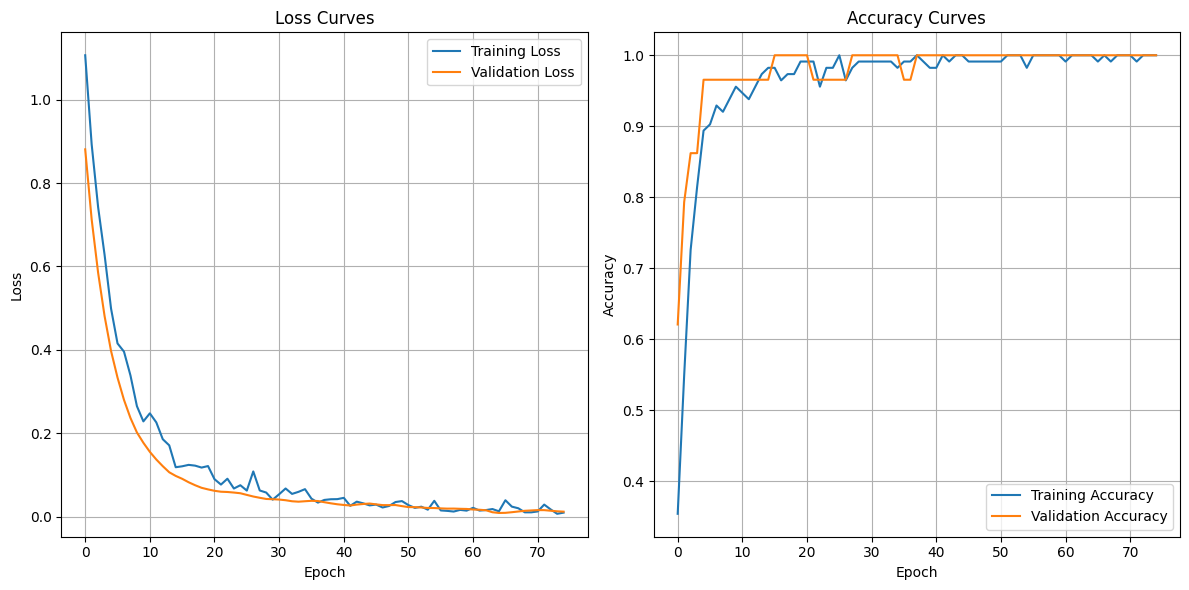

In [28]:
plt.figure(figsize=(12, 6))

# Plot loss curves
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot accuracy curves
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Step 7: Model Evaluation

Evaluation Requirements:
- Predict class labels on the test set
- Compute Confusion Matrix
- Visualize Confusion Matrix using heatmap
- Print Classification Report


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


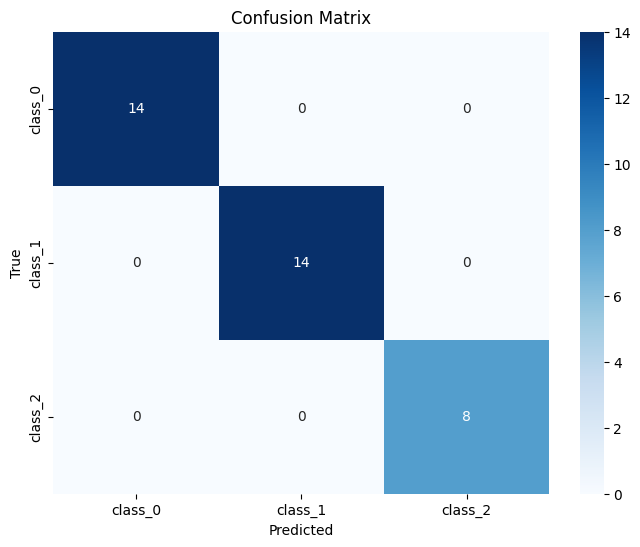

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [ ]:
# Predict probabilities on test data
y_pred_prob = model.predict(X_test)

# Convert probabilities to class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Confusion Matrix
cm = confusion_matrix(np.argmax(y_test, axis=1), y_pred)

# Plot Confusion Matrix as heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names,
            yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


# Classification Report
print(classification_report(np.argmax(y_test, axis=1), y_pred))

# Key Observations

1. Dropout in deep neural networks is used to switch off a random set of neurons (nodes) along with their connections during the training phase

2. EarlyStopping is a regularization technique used to prevent overfitting and save computational resources by halting the training of a machine learning model at the optimal moment. Instead of training for a fixed number of epochs, it monitors the model's performance on a separate validation set and stops training once that performance begins to degrade.

3. Softmax is required for multiclass classification because it converts raw model outputs (logits) into a coherent probability distribution over multiple mutually exclusive classes. It ensures that each output value is between 0 and 1, and the total sum of all outputs equals 1.

4. Using Mean Squared Error (MSE) instead of categorical_crossentropy for classification tasks—while technically possible—generally leads to poor performance, slow convergence, and less confident models.